# Inference-Time Exogenous Imputation & Marginalization Benchmark (`HCMC Daily`)

Notebook trình diễn thực nghiệm (**Presentation Layer** — toàn bộ logic chạy & metric được tách gọn trong [`exogenous_imputer.py`](../../exogenous_imputer.py), [`imputation_benchmark.py`](../../imputation_benchmark.py), [`imputation_reporting.py`](../../imputation_reporting.py) và [`imputation_baselines.py`](../../imputation_baselines.py)).

## Tổng quan Kiến trúc & Guardrails
- **Cô lập Serving:** API `POST /predict` và automated pipeline giữ nguyên fail-fast (`COMPLETE_ALL_35`, zero real-time imputation).
- **Zero Data Leakage:** Mọi imputer baseline (`SimpleImputer`, `IterativeImputer`, `KNNImputer`, `doy_climatology`), TreeSHAP ranking và `ClimatologyLookupTable` / `HistoricalAnalogStore` đều fit/xây dựng **duy nhất trên `Dev_Train` (`2001-01-01 .. 2018-04-30`, 6,329 ngày)**.
- **Đánh giá sạch trên `Test`:** `48` rolling-origin anchors trải đều trên `Test` (`2020-05-01 .. 2026-04-23`, cách đều ~45 ngày), bao phủ đủ 3 giai đoạn khí hậu (`Dry`, `Transition`, `Wet`).
- **Mô hình đóng băng:** `SC-31` (`lightgbm_tweedie_F3`, 70 features — chính) & `SC-30` (`lightgbm_tweedie_F2`, 65 features — đối chiếu).
- **Ma trận 4 trục:** `Position (trailing, interior)` × `Length L ∈ {0, 3, 7, 14, 30, 60, 90}` × `Profile (A: 11 biến CERES SYN1deg, B: Top-5 SHAP, C: 34 biến ngoại sinh)` × `11 Methods (Tier 1–4)`.

In [1]:
# Bootstrap root & load persisted benchmark outputs (or run fresh if absent)
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / "src").exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from research.imputer_benchmark.imputation_benchmark import ImputationBenchmarkConfig, run_benchmark_execution
from research.imputer_benchmark.imputation_reporting import (
    DEFAULT_OUTPUT_DIR,
    build_summary_tables,
    evaluate_acceptance_gates,
    write_benchmark_artifacts,
)

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR = ROOT_DIR / DEFAULT_OUTPUT_DIR
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

summary_csv = OUT_DIR / "benchmark_summary_metrics.csv"
if not summary_csv.exists():
    out = run_benchmark_execution(ImputationBenchmarkConfig())
    tables = build_summary_tables(out)
    gates = evaluate_acceptance_gates(out, tables["summary_df"])
    write_benchmark_artifacts(out, tables, gates, output_dir=OUT_DIR)

meta = json.loads((OUT_DIR / "run_metadata.json").read_text(encoding="utf-8"))
summary_df = pd.read_csv(OUT_DIR / "benchmark_summary_metrics.csv")
horizon_df = pd.read_csv(OUT_DIR / "benchmark_horizon_breakdown.csv")
sensitivity_df = pd.read_csv(OUT_DIR / "benchmark_hybrid_sensitivity.csv")
wilcoxon_df = pd.read_csv(OUT_DIR / "benchmark_wilcoxon_tests.csv")
shap_df = pd.read_csv(OUT_DIR / "shap_exogenous_ranking.csv")
raw_df = pd.read_parquet(OUT_DIR / "benchmark_raw_predictions.parquet")

print(f"Loaded benchmark artifacts: {len(raw_df):,} raw rows | {meta['n_anchors']} anchors")
print(f"Dev_Train: {meta['dev_train_range']} | Test: {meta['test_range']}")

Loaded benchmark artifacts: 310,464 raw rows | 48 anchors
Dev_Train: ['2001-01-01', '2018-04-30', 6329] | Test: ['2020-05-01', '2026-04-30', 2191]


## 1. Automated Verification Gates (5 Kiểm định Tự động — Mục 7.2)

Xác nhận toàn bộ 5 gate tự động: Identity Check tại `L = 0` (`< 1e-9`), Zero-NaN Input Gate (trừ `raw_nan`), Domain Bounds (`0.0%` cho `custom_*`), Leakage Audit Gate, và Peak RSS Budget.

In [2]:
gates_info = meta["verification_gates"]
print("ALL GATES PASSED:", gates_info["all_passed"])
gate_rows = [{"gate": k, **v} for k, v in gates_info["gates"].items()]
display(pd.DataFrame(gate_rows))

ALL GATES PASSED: True


,gate,passed,max_abs_diff,threshold,failure_count,samples,max_violation_pct,dev_train,test,isolated_single_anchor_l90_profile_c_rss_mb,isolated_single_anchor_l90_profile_a_mode2_rss_mb,serving_rss_budget_mb,benchmark_runner_peak_rss_mb
0,1_identity_l0_max_abs_diff,True,0.0,1.000000e-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2_zero_nan_input_gate,True,NaN,NaN,0.0,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3_domain_bounds_custom_0pct,True,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,4_leakage_audit_split_order,True,NaN,NaN,NaN,NaN,NaN,2001-01-01..2018-04-30 (6329 rows),2020-05-01..2026-04-30 (2191 rows),NaN,NaN,NaN,NaN
4,5_memory_and_runtime_sanity,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,178.67,179.34,350.0,869.77


## 2. Kiểm toán SHAP trên `Dev_Train` (Xác định Hồ sơ B — Top-K Biến Ngoại sinh Chủ lực)

TreeSHAP (`pred_contrib=True`) được tính hoàn toàn trên `Dev_Train` sạch (`6,293` origins) của `SC-31` nhằm bảo đảm không rò rỉ dữ liệu Test.

,rank,model_id,variable_vi,variable_en,mean_abs_shap
0,1,SC-31,Độ ẩm tuyệt đối 2m,QV2M,0.159795
1,2,SC-31,Nhiệt độ 2m,T2M,0.153687
2,3,SC-31,Áp suất bề mặt,PS,0.120422
3,4,SC-31,Biên độ nhiệt 2m,T2M_RANGE,0.089388
4,5,SC-31,Bức xạ đỉnh khí quyển,TOA_SW_DWN,0.076439
5,6,SC-31,Điểm sương 2m,T2MDEW,0.069488
6,7,SC-31,Tốc độ gió 2m,WS2M,0.067924
7,8,SC-31,Độ ẩm tương đối 2m,RH2M,0.058150
8,9,SC-31,Hướng gió 10m,WD10M,0.035456
9,10,SC-31,Hướng gió 2m,WD2M,0.031204


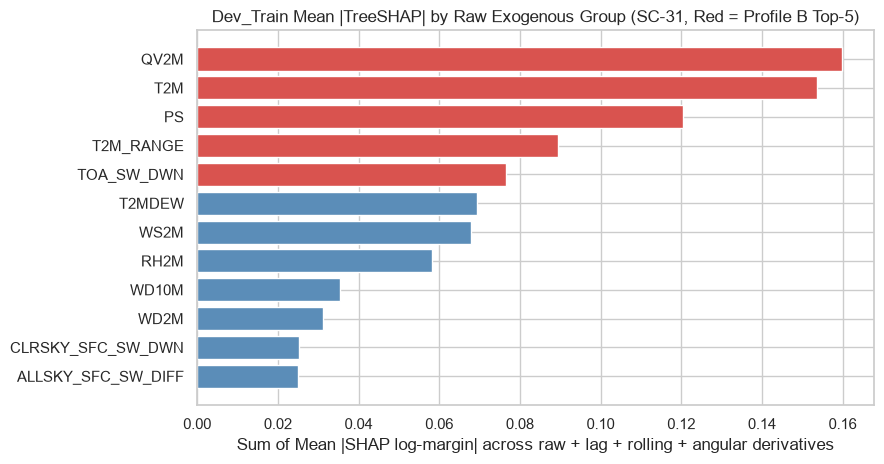

In [3]:
top12_shap = shap_df.head(12).copy()
display(top12_shap)

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_df = top12_shap.sort_values("mean_abs_shap", ascending=True)
colors = ["#d9534f" if r <= 5 else "#5b8db8" for r in plot_df["rank"]]
ax.barh(plot_df["variable_en"], plot_df["mean_abs_shap"], color=colors)
ax.set_title("Dev_Train Mean |TreeSHAP| by Raw Exogenous Group (SC-31, Red = Profile B Top-5)")
ax.set_xlabel("Sum of Mean |SHAP log-margin| across raw + lag + rolling + angular derivatives")
plt.tight_layout()
fig.savefig(FIG_DIR / "fig01_shap_top_exogenous.png", dpi=150)
plt.show()

## 3. Phân rã Đường cong Suy giảm Sai số theo $L$ (`Trailing` vs `Interior`, Profiles A/B/C)

So sánh mức suy giảm $\Delta\text{MAE}(\%)$ và `Fidelity-MAE` của 11 phương pháp (Tier 1–4) trên **`SC-31`**. Lưu ý: `linear_interp` không áp dụng cho `trailing` và `sklearn_iterative` được đánh dấu `NOT_APPLICABLE` tại Profile C.

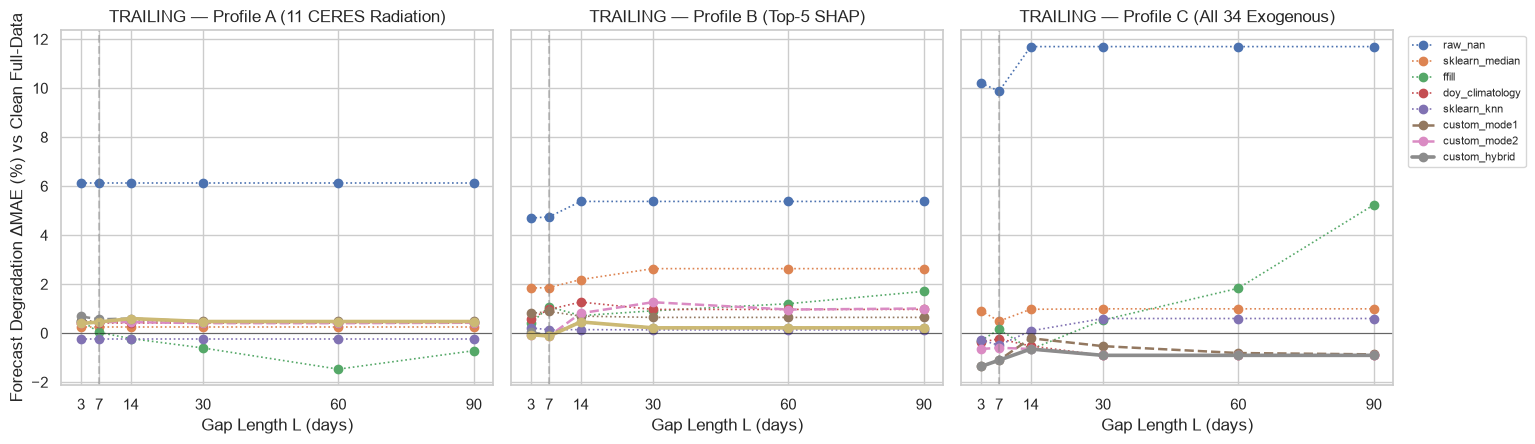

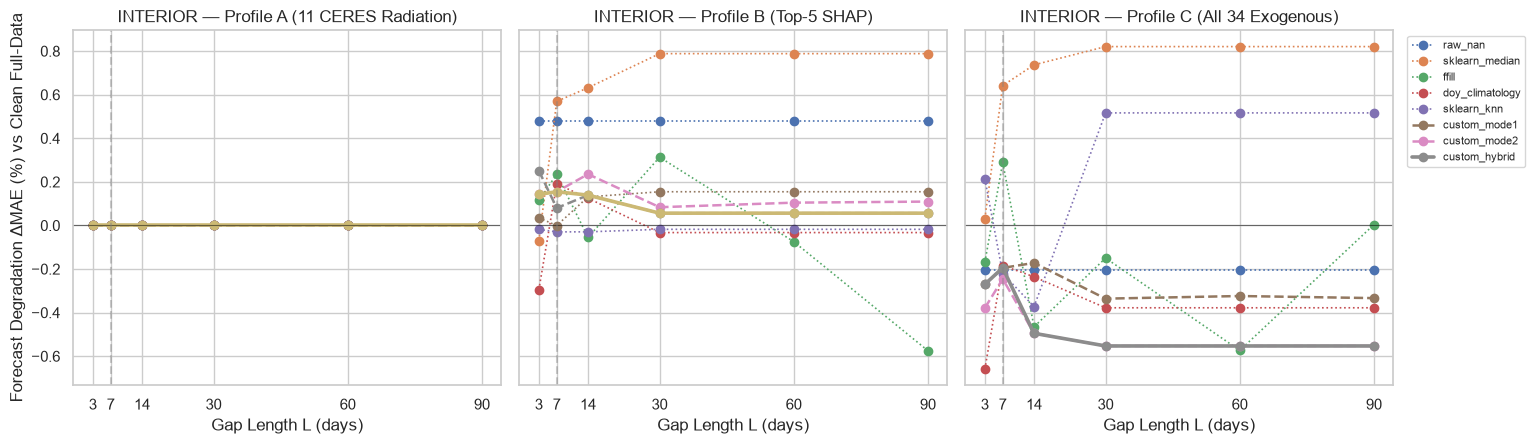

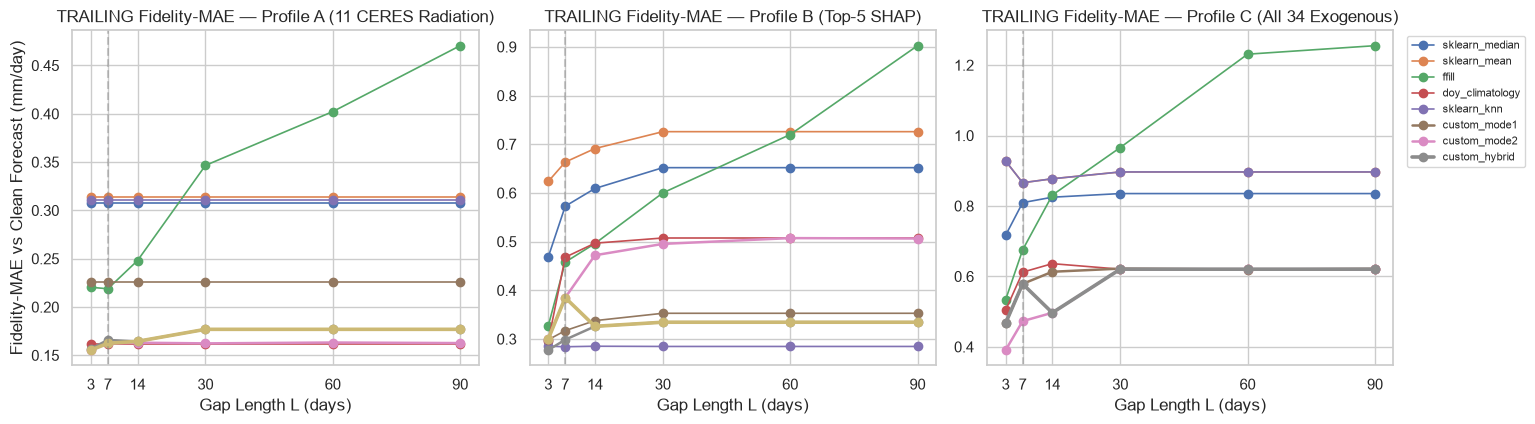

=== RANKING TABLE (SC-31) | Position=trailing | Profile=A | L in {3, 14, 90} ===


,gap_length,method,status,mae,rmse,mase,delta_mae_pct,fidelity_mae,rain_flip_rate_pct,domain_violation_pct
24,3,sklearn_mean,OK,3.860417,7.650282,1.042921,-0.256002,0.313721,2.678571,0.0
34,3,sklearn_iterative,OK,3.861693,7.658326,1.043266,-0.223034,0.310961,2.678571,0.0
26,3,sklearn_median,OK,3.879972,7.643919,1.048204,0.249256,0.308136,1.488095,0.0
38,3,custom_mode1,OK,3.885551,7.728547,1.049711,0.393396,0.155435,1.488095,0.0
42,3,custom_hybrid,OK,3.885551,7.728547,1.049711,0.393396,0.155435,1.488095,0.0
32,3,doy_climatology,OK,3.886020,7.728234,1.049838,0.405535,0.161977,1.488095,0.0
36,3,sklearn_knn,OK,3.889993,7.725776,1.050911,0.508182,0.225467,1.488095,0.0
28,3,ffill,OK,3.890165,7.723289,1.050958,0.512611,0.220401,1.785714,0.0
40,3,custom_mode2,OK,3.896651,7.733368,1.052710,0.680211,0.156834,0.892857,0.0
22,3,raw_nan,OK,4.107423,8.348922,1.109652,6.126046,1.377658,2.083333,NaN


=== RANKING TABLE (SC-31) | Position=trailing | Profile=B | L in {3, 14, 90} ===


,gap_length,method,status,mae,rmse,mase,delta_mae_pct,fidelity_mae,rain_flip_rate_pct,domain_violation_pct
192,3,custom_mode1,OK,3.867932,7.673163,1.044951,-0.061834,0.300011,2.380952,0.0
196,3,custom_hybrid,OK,3.867932,7.673163,1.044951,-0.061834,0.300011,2.380952,0.0
194,3,custom_mode2,OK,3.871494,7.694468,1.045914,0.030208,0.277296,3.273810,0.0
188,3,sklearn_iterative,OK,3.878642,7.707962,1.047845,0.214888,0.285198,1.785714,0.0
178,3,sklearn_mean,OK,3.882232,7.850867,1.048815,0.307665,0.623461,3.273810,0.0
182,3,ffill,OK,3.885870,7.658798,1.049798,0.401658,0.326911,1.785714,0.0
186,3,doy_climatology,OK,3.893222,7.697323,1.051784,0.591598,0.294995,2.380952,0.0
190,3,sklearn_knn,OK,3.901537,7.692673,1.054030,0.806458,0.298411,1.785714,0.0
180,3,sklearn_median,OK,3.941494,7.742856,1.064825,1.838834,0.468313,4.464286,0.0
176,3,raw_nan,OK,4.052159,8.229492,1.094722,4.698153,1.387062,9.821429,NaN


=== RANKING TABLE (SC-31) | Position=trailing | Profile=C | L in {3, 14, 90} ===


,gap_length,method,status,mae,rmse,mase,delta_mae_pct,fidelity_mae,rain_flip_rate_pct,domain_violation_pct
346,3,custom_mode1,OK,3.817609,7.635028,1.031356,-1.362045,0.467686,3.571429,0.0
350,3,custom_hybrid,OK,3.817609,7.635028,1.031356,-1.362045,0.467686,3.571429,0.0
348,3,custom_mode2,OK,3.845214,7.632852,1.038814,-0.648808,0.390847,3.571429,0.0
340,3,doy_climatology,OK,3.856102,7.669647,1.041755,-0.367481,0.504151,4.464286,0.0
336,3,ffill,OK,3.858493,7.600527,1.042401,-0.305701,0.533987,3.869048,0.0
332,3,sklearn_mean,OK,3.859386,7.958143,1.042643,-0.282643,0.927488,4.761905,0.0
344,3,sklearn_knn,OK,3.859386,7.958143,1.042643,-0.282643,0.927488,4.761905,0.0
334,3,sklearn_median,OK,3.905602,7.813586,1.055128,0.911479,0.716782,5.952381,0.0
330,3,raw_nan,OK,4.265473,8.516371,1.152350,10.209699,1.900429,13.988095,NaN
338,3,linear_interp,NOT_APPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (2 outputs left out)

=== RANKING TABLE (SC-31) | Position=interior | Profile=B | L in {3, 14, 90} ===


,gap_length,method,status,mae,rmse,mase,delta_mae_pct,fidelity_mae,rain_flip_rate_pct,domain_violation_pct
648,3,doy_climatology,OK,3.858891,7.725417,1.042509,-0.295428,0.095111,0.297619,0.0
642,3,sklearn_median,OK,3.867618,7.724727,1.044867,-0.069932,0.138100,1.190476,0.0
650,3,sklearn_iterative,OK,3.869612,7.720483,1.045405,-0.018421,0.001531,0.000000,0.0
652,3,sklearn_knn,OK,3.871674,7.723965,1.045962,0.034852,0.049566,0.000000,0.0
640,3,sklearn_mean,OK,3.872589,7.725320,1.046210,0.058499,0.110728,0.892857,0.0
644,3,ffill,OK,3.874831,7.718156,1.046815,0.116437,0.080407,0.297619,0.0
654,3,custom_mode1,OK,3.875848,7.720836,1.047090,0.142713,0.070724,0.297619,0.0
658,3,custom_hybrid,OK,3.875848,7.720836,1.047090,0.142713,0.070724,0.297619,0.0
646,3,linear_interp,OK,3.879266,7.721555,1.048013,0.231012,0.071780,0.297619,0.0
656,3,custom_mode2,OK,3.880049,7.719123,1.048225,0.251255,0.072434,0.297619,0.0


=== RANKING TABLE (SC-31) | Position=interior | Profile=C | L in {3, 14, 90} ===


,gap_length,method,status,mae,rmse,mase,delta_mae_pct,fidelity_mae,rain_flip_rate_pct,domain_violation_pct
802,3,doy_climatology,OK,3.844803,7.710997,1.038703,-0.659423,0.141311,1.190476,0.0
810,3,custom_mode2,OK,3.855653,7.700171,1.041634,-0.379076,0.119252,1.190476,0.0
808,3,custom_mode1,OK,3.859877,7.695661,1.042775,-0.269943,0.109497,0.595238,0.0
812,3,custom_hybrid,OK,3.859877,7.695661,1.042775,-0.269943,0.109497,0.595238,0.0
800,3,linear_interp,OK,3.861707,7.695142,1.043270,-0.222659,0.110869,0.595238,0.0
792,3,raw_nan,OK,3.862395,7.801602,1.043456,-0.204880,0.340116,2.976190,NaN
798,3,ffill,OK,3.863763,7.708401,1.043825,-0.169534,0.137854,0.892857,0.0
796,3,sklearn_median,OK,3.871536,7.719115,1.045925,0.031290,0.187834,1.785714,0.0
794,3,sklearn_mean,OK,3.878592,7.722391,1.047831,0.213604,0.168522,1.190476,0.0
806,3,sklearn_knn,OK,3.878592,7.722391,1.047831,0.213604,0.168522,1.190476,0.0


In [4]:
key_methods = [
    "raw_nan", "sklearn_mean", "sklearn_median", "ffill", "linear_interp",
    "doy_climatology", "sklearn_iterative", "sklearn_knn",
    "custom_mode1", "custom_mode2", "custom_hybrid",
]
sc31 = summary_df[(summary_df["model_id"] == "SC-31") & (summary_df["gap_length"] > 0)].copy()

for pos in ["trailing", "interior"]:
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), sharey=True)
    for ax, prof, title in zip(axes, ["A", "B", "C"], [
        "Profile A (11 CERES Radiation)",
        "Profile B (Top-5 SHAP)",
        "Profile C (All 34 Exogenous)",
    ]):
        sub = sc31[(sc31["position"] == pos) & (sc31["profile"] == prof) & (sc31["status"] == "OK")]
        for m in ["raw_nan", "sklearn_median", "ffill", "doy_climatology", "sklearn_iterative", "sklearn_knn", "custom_mode1", "custom_mode2", "custom_hybrid"]:
            m_sub = sub[sub["method"] == m].sort_values("gap_length")
            if m_sub.empty:
                continue
            lw = 2.6 if m == "custom_hybrid" else (1.8 if m.startswith("custom") else 1.2)
            ls = "-" if m == "custom_hybrid" else ("--" if m.startswith("custom") else ":")
            ax.plot(m_sub["gap_length"], m_sub["delta_mae_pct"], marker="o", linewidth=lw, linestyle=ls, label=m)
        ax.axhline(0.0, color="black", linewidth=0.8, alpha=0.5)
        ax.axvline(7, color="gray", linestyle="--", alpha=0.4)
        ax.set_title(f"{pos.upper()} — {title}")
        ax.set_xlabel("Gap Length L (days)")
        ax.set_xticks([3, 7, 14, 30, 60, 90])
    axes[0].set_ylabel("Forecast Degradation ΔMAE (%) vs Clean Full-Data")
    axes[-1].legend(bbox_to_anchor=(1.02, 1.0), loc="upper left", fontsize=8)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"fig02_degradation_{pos}_sc31.png", dpi=150)
    plt.show()

# Prediction Fidelity-MAE (Branch 2A) curves on Trailing across Profiles A, B, C
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4), sharey=False)
for ax, prof, title in zip(axes, ["A", "B", "C"], [
    "Profile A (11 CERES Radiation)",
    "Profile B (Top-5 SHAP)",
    "Profile C (All 34 Exogenous)",
]):
    sub = sc31[(sc31["position"] == "trailing") & (sc31["profile"] == prof) & (sc31["status"] == "OK") & (sc31["method"] != "raw_nan")]
    for m in ["sklearn_median", "sklearn_mean", "ffill", "doy_climatology", "sklearn_iterative", "sklearn_knn", "custom_mode1", "custom_mode2", "custom_hybrid"]:
        m_sub = sub[sub["method"] == m].sort_values("gap_length")
        if m_sub.empty:
            continue
        lw = 2.6 if m == "custom_hybrid" else (1.8 if m.startswith("custom") else 1.2)
        ax.plot(m_sub["gap_length"], m_sub["fidelity_mae"], marker="o", linewidth=lw, label=m)
    ax.axvline(7, color="gray", linestyle="--", alpha=0.4)
    ax.set_title(f"TRAILING Fidelity-MAE — {title}")
    ax.set_xlabel("Gap Length L (days)")
    ax.set_xticks([3, 7, 14, 30, 60, 90])
axes[0].set_ylabel("Fidelity-MAE vs Clean Forecast (mm/day)")
axes[-1].legend(bbox_to_anchor=(1.02, 1.0), loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig02b_fidelity_mae_trailing_sc31.png", dpi=150)
plt.show()

for pos in ["trailing", "interior"]:
    for prof in ["A", "B", "C"]:
        print(f"=== RANKING TABLE (SC-31) | Position={pos} | Profile={prof} | L in {{3, 14, 90}} ===")
        tbl = (
            sc31[(sc31["position"] == pos) & (sc31["profile"] == prof) & (sc31["gap_length"].isin([3, 14, 90]))]
            [["gap_length", "method", "status", "mae", "rmse", "mase", "delta_mae_pct", "fidelity_mae", "rain_flip_rate_pct", "domain_violation_pct"]]
            .sort_values(["gap_length", "mae"])
        )
        display(tbl)

## 4. Nhánh 1 (Intrinsic) & Tránh Bẫy Double-Penalty (`VR_scen` vs `VR_mean`)

Với Chế độ 2 (`custom_mode2`, `custom_hybrid`), các chỉ số cấu trúc (`Variance Ratio`, `FE Fidelity`, `Cross-Corr Error`) được tính trên **từng kịch bản trước khi lấy trung bình theo $w_k$** (`*_scen`), đặt cạnh giá trị tính trên chuỗi trung bình (`*_mean`) để kiểm chứng hiện tượng làm phẳng tín hiệu nếu cộng gộp sớm.

,gap_length,method,nmae_mean,nrmse_mean,vr_scen,vr_mean,fe_fidelity_nmae_scen,cross_corr_err_scen,domain_violation_pct
82,14,custom_mode1,0.489122,0.601174,1.982872e-01,1.982872e-01,0.492348,0.478045,0.0
76,14,doy_climatology,0.497334,0.610453,1.241675e-01,1.241675e-01,0.492816,0.555792,0.0
84,14,custom_mode2,0.530142,0.638338,1.643264e+00,4.013446e-01,0.455457,0.276149,0.0
86,14,custom_hybrid,0.530142,0.638338,1.643264e+00,4.013446e-01,0.455457,0.276149,0.0
80,14,sklearn_knn,0.547630,0.667169,1.085760e+01,1.085760e+01,0.438292,0.287303,0.0
72,14,ffill,0.659771,0.781608,1.681588e-27,1.681588e-27,0.562125,0.752279,0.0
104,30,custom_mode1,0.519345,0.659919,1.922822e-01,1.922822e-01,0.492696,0.434404,0.0
98,30,doy_climatology,0.528742,0.671048,1.715537e-01,1.715537e-01,0.492816,0.514901,0.0
106,30,custom_mode2,0.545945,0.683791,1.209892e+00,3.531657e-01,0.453823,0.204293,0.0
108,30,custom_hybrid,0.545945,0.683791,1.209892e+00,3.531657e-01,0.453823,0.204293,0.0


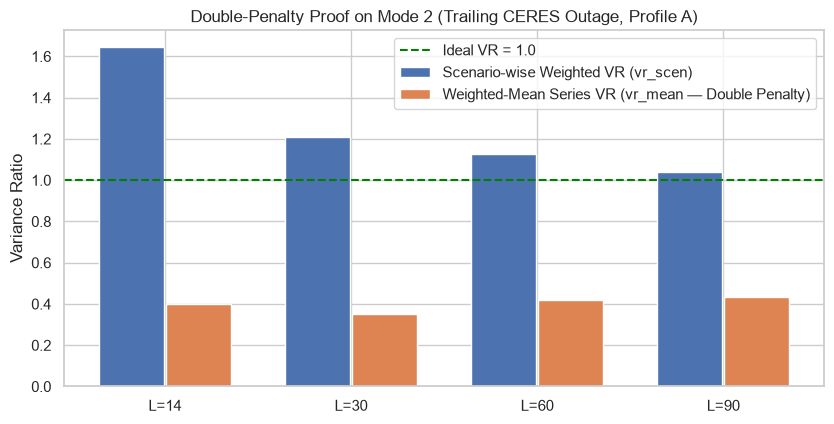

In [5]:
dp_sub = sc31[(sc31["position"] == "trailing") & (sc31["profile"] == "A") & (sc31["gap_length"] >= 14) & (sc31["method"].isin(["doy_climatology", "ffill", "sklearn_knn", "custom_mode1", "custom_mode2", "custom_hybrid"]))][
    ["gap_length", "method", "nmae_mean", "nrmse_mean", "vr_scen", "vr_mean", "fe_fidelity_nmae_scen", "cross_corr_err_scen", "domain_violation_pct"]
].sort_values(["gap_length", "nmae_mean"])
display(dp_sub)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
m2_dp = dp_sub[dp_sub["method"] == "custom_mode2"].sort_values("gap_length")
x = np.arange(len(m2_dp))
ax.bar(x - 0.18, m2_dp["vr_scen"], width=0.35, label="Scenario-wise Weighted VR (vr_scen)")
ax.bar(x + 0.18, m2_dp["vr_mean"], width=0.35, label="Weighted-Mean Series VR (vr_mean — Double Penalty)")
ax.axhline(1.0, color="green", linestyle="--", label="Ideal VR = 1.0")
ax.set_xticks(x)
ax.set_xticklabels([f"L={int(g)}" for g in m2_dp["gap_length"]])
ax.set_ylabel("Variance Ratio")
ax.set_title("Double-Penalty Proof on Mode 2 (Trailing CERES Outage, Profile A)")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "fig03_double_penalty_vr.png", dpi=150)
plt.show()

## 5. Phân rã Chân trời $h = 1 \dots 7$ (Profile B Top-K SHAP) & Đối chiếu `SC-31` vs `SC-30`

Kiểm tra phân rã sai số từng ngày dự báo $h=1\dots 7$ tại `L ∈ {3, 14, 90}` cho cả `SC-31` (F3) và `SC-30` (F2).

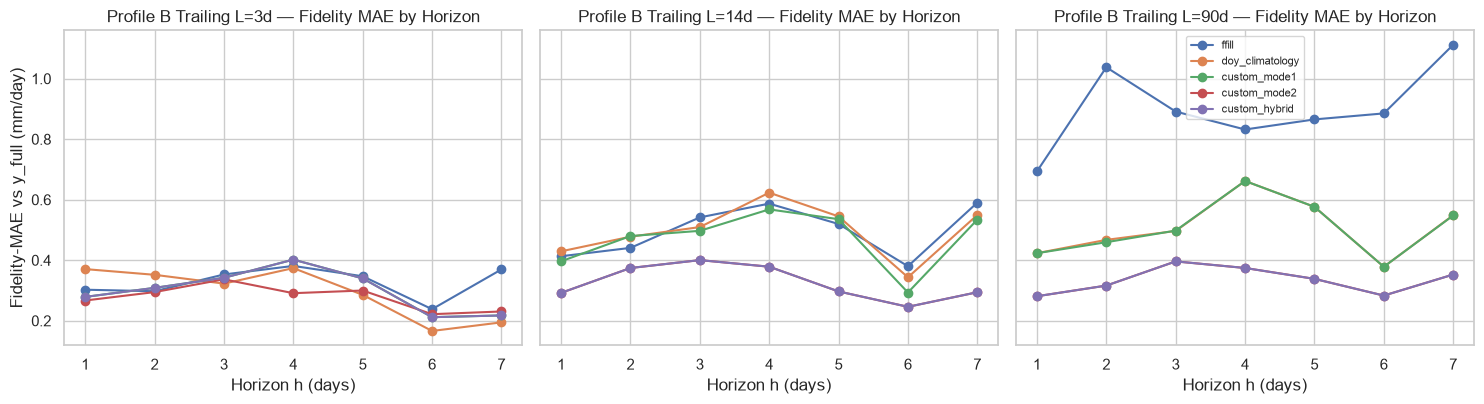

,model_id,profile,method,mean_mae,mean_fidelity_mae,mean_delta_mae_pct
0,SC-30,A,custom_hybrid,3.833011,0.175104,-0.137440
1,SC-30,A,custom_mode1,3.842601,0.161596,0.112425
2,SC-30,A,custom_mode2,3.834466,0.177035,-0.099537
3,SC-30,A,doy_climatology,3.845313,0.166517,0.183061
4,SC-30,B,custom_hybrid,3.852061,0.342238,0.358868
5,SC-30,B,custom_mode1,3.866677,0.429641,0.739676
6,SC-30,B,custom_mode2,3.858270,0.330762,0.520650
7,SC-30,B,doy_climatology,3.880107,0.448470,1.089564
8,SC-30,C,custom_hybrid,3.781649,0.570458,-1.475593
9,SC-30,C,custom_mode1,3.777683,0.574566,-1.578922


In [6]:
h_prof_b = horizon_df[
    (horizon_df["model_id"] == "SC-31")
    & (horizon_df["position"] == "trailing")
    & (horizon_df["profile"] == "B")
    & (horizon_df["gap_length"].isin([3, 14, 90]))
    & (horizon_df["method"].isin(["ffill", "doy_climatology", "custom_mode1", "custom_mode2", "custom_hybrid"]))
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, L in zip(axes, [3, 14, 90]):
    sub = h_prof_b[h_prof_b["gap_length"] == L]
    for m in ["ffill", "doy_climatology", "custom_mode1", "custom_mode2", "custom_hybrid"]:
        ms = sub[sub["method"] == m].sort_values("horizon")
        ax.plot(ms["horizon"], ms["fidelity_mae"], marker="o", label=m)
    ax.set_title(f"Profile B Trailing L={L}d — Fidelity MAE by Horizon")
    ax.set_xlabel("Horizon h (days)")
    ax.set_xticks(range(1, 8))
axes[0].set_ylabel("Fidelity-MAE vs y_full (mm/day)")
axes[-1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig04_horizon_breakdown_profile_b.png", dpi=150)
plt.show()

comp_models = (
    summary_df[(summary_df["gap_length"] > 0) & (summary_df["position"] == "trailing") & (summary_df["method"].isin(["doy_climatology", "custom_mode1", "custom_mode2", "custom_hybrid"]))]
    .groupby(["model_id", "profile", "method"], as_index=False)
    .agg(mean_mae=("mae", "mean"), mean_fidelity_mae=("fidelity_mae", "mean"), mean_delta_mae_pct=("delta_mae_pct", "mean"))
)
display(comp_models)

## 6. Ablation `Mode 1` vs `Mode 2` vs `Hybrid`, Quét Ngưỡng $L^* \in \{3, 5, 7, 14\}$ & Kiểm định Tin cậy $\sigma_{\text{imp}}$

In [7]:
sens_tbl = (
    sensitivity_df[(sensitivity_df["model_id"] == "SC-31") & (sensitivity_df["gap_length"] > 0)]
    .groupby(["position", "threshold_l_star"], as_index=False)
    .agg(
        mean_mae=("mae", "mean"),
        mean_rmse=("rmse", "mean"),
        mean_fidelity_mae=("fidelity_mae", "mean"),
        mean_delta_mae_pct=("delta_mae_pct", "mean"),
    )
)
display(sens_tbl)

sigma_rel = sc31[sc31["method"].isin(["custom_mode2", "custom_hybrid"]) & sc31["spearman_sigma_rho"].notna()][
    ["position", "profile", "gap_length", "method", "spearman_sigma_rho", "spearman_sigma_p"]
]
display(sigma_rel.sort_values(["position", "profile", "gap_length"]))

,position,threshold_l_star,mean_mae,mean_rmse,mean_fidelity_mae,mean_delta_mae_pct
0,interior,3,3.865726,7.717065,0.083174,-0.118828
1,interior,5,3.865726,7.717065,0.083174,-0.118828
2,interior,7,3.865995,7.718460,0.081881,-0.111862
3,interior,14,3.866897,7.720417,0.082393,-0.088570
4,trailing,3,3.867331,7.683982,0.346844,-0.077341
5,trailing,5,3.867331,7.683982,0.346844,-0.077341
6,trailing,7,3.865913,7.673497,0.357316,-0.113998
7,trailing,14,3.867304,7.661971,0.371820,-0.078056


,position,profile,gap_length,method,spearman_sigma_rho,spearman_sigma_p
656,interior,B,3,custom_mode2,0.866729,6.353369e-103
678,interior,B,7,custom_mode2,0.805881,5.096622e-78
700,interior,B,14,custom_mode2,0.751752,2.336892e-62
702,interior,B,14,custom_hybrid,0.751752,2.336892e-62
722,interior,B,30,custom_mode2,0.733621,5.456381e-58
724,interior,B,30,custom_hybrid,0.733621,5.456381e-58
744,interior,B,60,custom_mode2,0.733621,5.456381e-58
746,interior,B,60,custom_hybrid,0.733621,5.456381e-58
766,interior,B,90,custom_mode2,0.733621,5.456381e-58
768,interior,B,90,custom_hybrid,0.733621,5.456381e-58


## 7. Kiểm định Ý nghĩa Thống kê (Wilcoxon + Holm–Bonferroni) & Hồ sơ SLA Tài nguyên

Kiểm định Wilcoxon ghép cặp theo anchor giữa `custom_hybrid` và đối thủ mạnh nhất ở Tầng 3 (`doy_climatology` / `sklearn_iterative` / `sklearn_knn`) cùng độ trễ `P50/P95 (ms)` tách riêng bước điền khuyết vs `FE + Predict`.

In [8]:
display(wilcoxon_df[wilcoxon_df["model_id"] == "SC-31"].sort_values(["position", "profile", "gap_length"]))

sla_tbl = (
    sc31[(sc31["position"] == "trailing") & (sc31["profile"] == "A") & (sc31["gap_length"].isin([7, 30, 90]))]
    [["gap_length", "method", "impute_ms_p50", "impute_ms_p95", "fe_predict_ms_p50", "total_ms_p50", "total_ms_p95"]]
    .sort_values(["gap_length", "total_ms_p50"])
)
display(sla_tbl)

print("Resource SLA summary:", json.dumps(meta["verification_gates"]["gates"]["5_memory_and_runtime_sanity"], indent=2))

,model_id,position,profile,gap_length,best_tier3_method,best_tier3_fidelity_method,hybrid_mean_anchor_mae,tier3_mean_anchor_mae,mean_diff_mae,hybrid_mean_fidelity_mae,...,p_one_sided_raw,p_two_sided_raw,p_fid_one_sided_raw,p_fid_two_sided_raw,p_one_sided_holm,p_two_sided_holm,significant_one_sided_005,p_fid_one_sided_holm,p_fid_two_sided_holm,significant_fidelity_005
18,SC-31,interior,A,3,doy_climatology,doy_climatology,3.870325,3.870325,0.000000e+00,0.000000e+00,...,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000,False,1.000000,1.000000e+00,False
19,SC-31,interior,A,7,doy_climatology,doy_climatology,3.870325,3.870325,0.000000e+00,0.000000e+00,...,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000,False,1.000000,1.000000e+00,False
20,SC-31,interior,A,14,doy_climatology,doy_climatology,3.870325,3.870325,-6.187180e-17,2.728059e-16,...,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000,False,1.000000,1.000000e+00,False
21,SC-31,interior,A,30,doy_climatology,doy_climatology,3.870325,3.870325,1.590163e-17,3.241764e-16,...,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000,False,1.000000,1.000000e+00,False
22,SC-31,interior,A,60,doy_climatology,doy_climatology,3.870325,3.870325,1.590163e-17,3.241764e-16,...,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000,False,1.000000,1.000000e+00,False
23,SC-31,interior,A,90,doy_climatology,doy_climatology,3.870325,3.870325,1.590163e-17,3.241764e-16,...,1.000000,1.000000,1.000000,1.000000e+00,1.000000,1.000000,False,1.000000,1.000000e+00,False
24,SC-31,interior,B,3,doy_climatology,sklearn_iterative,3.875848,3.858891,1.695749e-02,7.072352e-02,...,0.987254,0.025492,1.000000,1.568649e-08,1.000000,0.152951,False,1.000000,1.568649e-08,False
25,SC-31,interior,B,7,sklearn_iterative,sklearn_iterative,3.876314,3.869185,7.128967e-03,1.009075e-01,...,0.760839,0.478322,1.000000,2.396832e-09,1.000000,1.000000,False,1.000000,4.793664e-09,False
26,SC-31,interior,B,14,sklearn_iterative,sklearn_iterative,3.875705,3.869185,6.519861e-03,1.013097e-01,...,0.703302,0.600464,1.000000,7.105427e-15,1.000000,1.000000,False,1.000000,4.263256e-14,False
27,SC-31,interior,B,30,doy_climatology,sklearn_iterative,3.872504,3.869058,3.445434e-03,1.195464e-01,...,0.578541,0.850878,1.000000,7.105427e-15,1.000000,1.000000,False,1.000000,4.263256e-14,False


,gap_length,method,impute_ms_p50,impute_ms_p95,fe_predict_ms_p50,total_ms_p50,total_ms_p95
52,7,linear_interp,0.02940,0.037035,0.00000,0.02940,0.037035
44,7,raw_nan,1.52215,1.990550,22.31805,23.78045,30.801140
46,7,sklearn_mean,4.33185,5.657135,27.31000,31.77650,35.324085
48,7,sklearn_median,4.50125,6.521350,27.85555,32.40675,41.528945
54,7,doy_climatology,5.17580,7.199020,27.92370,33.12915,42.560870
50,7,ffill,5.25620,7.073540,28.00410,33.27335,42.774005
56,7,sklearn_iterative,7.18780,11.014725,28.22975,35.45505,49.534195
58,7,sklearn_knn,18.52160,24.056310,29.10435,47.62345,60.843225
60,7,custom_mode1,22.88215,32.326385,28.49225,51.50245,69.459575
64,7,custom_hybrid,22.88215,32.326385,28.49225,51.50245,69.459575


Resource SLA summary: {
  "passed": true,
  "isolated_single_anchor_l90_profile_c_rss_mb": 178.67,
  "isolated_single_anchor_l90_profile_a_mode2_rss_mb": 179.34,
  "serving_rss_budget_mb": 350.0,
  "benchmark_runner_peak_rss_mb": 869.77
}
